# Language labels

Prepares review material and checks the language labels for the cooking episodes.

## Settings

Flags for the review material. Change them here before running.

In [16]:
FORCE = False
MAKE_STORYBOARD = True
STORYBOARD_STEP_S = 5
MAKE_REVIEW_VIDEO = True
REVIEW_STEP_S = 0.5
REVIEW_PLAY_FPS = 10
PANEL_HEIGHT = 270

## Imports and helpers

Small functions that the later steps use.

In [17]:
import json
import re
import shutil
import subprocess
import tempfile
import zipfile
from collections import Counter
from datetime import datetime
from pathlib import Path

import av
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from tqdm import tqdm

FPS = 30
FONT = cv2.FONT_HERSHEY_SIMPLEX
CAMS = ["cam_high", "cam_left_wrist", "cam_right_wrist", "cam_ext"]
SHORT = {"cam_high": "high", "cam_left_wrist": "left", "cam_right_wrist": "right", "cam_ext": "ext"}


def iso_to_ns(s):
    t = pd.Timestamp(s)
    if t.tzinfo is None:
        t = t.tz_localize("UTC")
    return int(t.as_unit("ns").value)


def find_key(keys, *words):
    # exact name first, then any key that contains all the words
    for k in keys:
        if k.lower() in words:
            return k
    for k in keys:
        if all(w in k.lower() for w in words):
            return k
    return None


def fmt_mmss(t):
    return f"{int(t // 60):02d}:{int(t % 60):02d}"


def pick(meta, key, row, col):
    if meta.get(key) not in (None, ""):
        return meta[key]
    if row is not None and col in row.index:
        return row[col]
    return ""


class FrameReader:
    # reads a raw h264 file frame by frame, the stream is never kept in memory
    def __init__(self, path):
        self.c = av.open(str(path), format="h264")
        s = self.c.streams.video[0]
        s.thread_type = "AUTO"
        self.it = self.c.decode(s)
        self.i = -1
        self.frame = None
        self.done = False
        self.img = None
        self.img_i = -2

    def get(self, idx):
        # move forward to frame idx, if idx is behind us the current frame is returned
        while self.i < idx and not self.done:
            try:
                self.frame = next(self.it)
                self.i += 1
            except StopIteration:
                self.done = True
        if self.frame is None:
            return None
        if self.img_i != self.i:
            self.img = self.frame.to_ndarray(format="bgr24")
            self.img_i = self.i
        return self.img

    def close(self):
        self.c.close()


def count_frames(path):
    try:
        with av.open(str(path), format="h264") as c:
            s = c.streams.video[0]
            return sum(1 for p in c.demux(s) if p.size > 0)
    except Exception as e:
        print("could not count frames in", Path(path).name, "-", e)
        return 0


_size_cache = {}


def video_size(path):
    # returns (height, width) of the first frame
    key = str(path)
    if key not in _size_cache:
        rd = FrameReader(path)
        try:
            img = rd.get(0)
        finally:
            rd.close()
        if img is None:
            raise RuntimeError("no frames in " + Path(path).name)
        _size_cache[key] = (img.shape[0], img.shape[1])
    return _size_cache[key]


def save_csv(df, path, bom=False):
    df.to_csv(path, index=False, encoding="utf-8-sig" if bom else "utf-8")

## Setup

Loads the config and the episode list, counts the video frames and checks that all files exist.

In [18]:
ROOT = Path.cwd().resolve().parent
if not (ROOT / "configs" / "config.yaml").exists():
    raise RuntimeError("configs\\config.yaml not found in " + str(ROOT) + ". open this notebook from the notebooks folder of the project.")

REPORTS = ROOT / "reports"
EPDIR = ROOT / "episodes"
INTERIM = ROOT / "interim" / "review_lang"
REPORTS.mkdir(exist_ok=True)

cfg = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text(encoding="utf-8"))
print("project root:", ROOT)
print("config keys:", list(cfg)[:8] if isinstance(cfg, dict) else type(cfg).__name__)

# state that later cells fill in
story_pages = {}
review_info = {}
hints_count = {}
hints_df = pd.DataFrame(columns=["episode_id", "kind", "start_time", "end_time", "duration_s"])
templates_written = []
have_labels = False
labels_ok = False
check_df = None
ep_df = None
hyp_df = None
phr = {}

episode_ids = []
csv_rows = {}
try:
    summary06 = json.loads((REPORTS / "06_summary.json").read_text(encoding="utf-8"))
    episode_ids = [str(x) for x in summary06["episode_ids"]]
    ep_csv = pd.read_csv(REPORTS / "05_episodes.csv", dtype=str)
    id_col = next((c for c in ("id", "episode_id") if c in ep_csv.columns), ep_csv.columns[0])
    for i, eid in enumerate(episode_ids):
        m = ep_csv[ep_csv[id_col] == eid]
        if len(m):
            csv_rows[eid] = m.iloc[0]
        elif i < len(ep_csv):
            csv_rows[eid] = ep_csv.iloc[i]
except Exception as e:
    print("problem reading the episode list:", repr(e))

eps = {}
for eid in episode_ids:
    d = EPDIR / eid
    try:
        meta = json.loads((d / "episode_metadata_draft.json").read_text(encoding="utf-8"))
        row = csv_rows.get(eid)
        eps[eid] = {
            "dir": d,
            "duration": float(pick(meta, "duration_sec", row, "duration_s")),
            "start_ns": iso_to_ns(meta["capture_start_iso"]),
            "task_id": pick(meta, "task_id", row, "task_id"),
            "task_name": pick(meta, "task_name", row, "task_name"),
            "max_timesteps": meta.get("max_timesteps"),
            "frames": {},
        }
    except Exception as e:
        print("episode", eid, "left out:", repr(e))


def ep_files(d):
    f = [d / "episode_metadata_draft.json"]
    f += [d / f"frames_{s}.npz" for s in ("head", "left", "right")]
    f += [d / "video" / f"{c}.h264" for c in CAMS]
    f.append(d / "video" / "cam_ext_timestamps.npz")
    return f


missing = [p for eid in episode_ids for p in ep_files(EPDIR / eid) if not p.exists()]
if missing:
    print("missing files:", len(missing))
    for p in missing[:10]:
        print("  ", p.relative_to(ROOT))
else:
    print("all files found")

for eid, ep in tqdm(eps.items(), desc="counting frames", mininterval=5, leave=False):
    for cam in CAMS:
        p = ep["dir"] / "video" / f"{cam}.h264"
        ep["frames"][cam] = count_frames(p) if p.exists() else 0

rows = []
for eid, ep in eps.items():
    r = {"episode_id": eid, "duration_s": round(ep["duration"], 1), "steps": ep["max_timesteps"]}
    for cam in CAMS:
        r[SHORT[cam]] = ep["frames"][cam]
    rows.append(r)
print("episodes:", list(eps))
if rows:
    print(pd.DataFrame(rows).to_string(index=False))

project root: C:\workstation\3RD YEAR\ego_pipeline
config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
all files found


episodes: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
                    episode_id  duration_s  steps  high  left  right   ext
vendorX_2026-10-11_op01_000001       708.0  21240 21240 21239  21239 21269
vendorX_2026-10-11_op01_000002       313.0   9390  9390  9390   9390  9403
vendorX_2026-10-11_op01_000003       347.0  10410 10410 10410  10409 10423
vendorX_2026-10-11_op01_000004       600.0  18000 18000 17999  17999 18024


## Episode clock

Builds the episode time in seconds for every frame of every camera. Also a helper that gives the nearest frame for a time.

In [19]:
clock = {}

for eid, ep in eps.items():
    clock[eid] = {}
    for cam in CAMS[:3]:
        clock[eid][cam] = np.arange(ep["frames"][cam]) / FPS
    clock[eid]["cam_ext"] = np.array([])
    try:
        with np.load(ep["dir"] / "video" / "cam_ext_timestamps.npz") as z:
            k = find_key(z.files, "utc")
            if k is None:
                raise KeyError("no utc array, keys are " + str(z.files))
            ts = np.asarray(z[k]).astype(np.int64)
        t = (ts - ep["start_ns"]) / 1e9
        clock[eid]["cam_ext"] = t
        n_vid = ep["frames"]["cam_ext"]
        if n_vid and len(t) != n_vid:
            print(eid, "note: cam_ext has", n_vid, "video frames but", len(t), "timestamps")
    except Exception as e:
        print(eid, "cam_ext clock failed:", repr(e))

# keys of the npz files for the first episode
first = next(iter(eps), None)
if first is not None:
    for name in ("frames_head.npz", "frames_left.npz", "frames_right.npz", "video/cam_ext_timestamps.npz"):
        p = eps[first]["dir"] / name
        try:
            with np.load(p) as z:
                print(name, {k: z[k].shape for k in z.files})
        except Exception as e:
            print(name, "could not be read:", repr(e))


def nearest_frame(eid, cam, t):
    # nearest frame index of a camera for an episode time (scalar or array)
    arr = clock[eid][cam]
    scalar = np.ndim(t) == 0
    t = np.atleast_1d(np.asarray(t, dtype=float))
    order = np.argsort(arr, kind="stable")
    s = arr[order]
    pos = np.searchsorted(s, t)
    lo = np.clip(pos - 1, 0, len(s) - 1)
    hi = np.clip(pos, 0, len(s) - 1)
    pick_hi = np.abs(s[hi] - t) < np.abs(s[lo] - t)
    idx = order[np.where(pick_hi, hi, lo)]
    return int(idx[0]) if scalar else idx


rows = []
for eid, ep in eps.items():
    for cam in CAMS:
        a = clock[eid][cam]
        rows.append({
            "episode_id": eid,
            "camera": cam,
            "frames": len(a),
            "first_s": round(float(a[0]), 3) if len(a) else None,
            "last_s": round(float(a[-1]), 3) if len(a) else None,
        })
        if len(a) and abs(a[-1] - ep["duration"]) > 1.0:
            print(eid, cam, "note: last frame is at", round(float(a[-1]), 1), "s, duration is", round(ep["duration"], 1), "s")
if rows:
    print(pd.DataFrame(rows).to_string(index=False))

frames_head.npz {'ts_session_us': (21240,), 'flags': (21240,), 'source_clip': (21240,), 'local_i': (21240,), 'global_n': (21240,), 'acc': (21240, 3), 'gyro': (21240, 3), 'source_clips': (5,)}
frames_left.npz {'ts_session_us': (21239,), 'flags': (21239,), 'source_clip': (21239,), 'local_i': (21239,), 'global_n': (21239,), 'acc': (21239, 3), 'gyro': (21239, 3), 'source_clips': (5,)}
frames_right.npz {'ts_session_us': (21239,), 'flags': (21239,), 'source_clip': (21239,), 'local_i': (21239,), 'global_n': (21239,), 'acc': (21239, 3), 'gyro': (21239, 3), 'source_clips': (5,)}
video/cam_ext_timestamps.npz {'pts_s': (21269,), 'ts_utc_ns': (21269,), 'flag': (21269,), 'root_frame_idx': (21269,)}
                    episode_id          camera  frames  first_s  last_s
vendorX_2026-10-11_op01_000001        cam_high   21240    0.000 707.967
vendorX_2026-10-11_op01_000001  cam_left_wrist   21239    0.000 707.933
vendorX_2026-10-11_op01_000001 cam_right_wrist   21239    0.000 707.933
vendorX_2026-10-1

## Storyboard

Saves JPEG pages with one frame every few seconds. Each cell has the cam_ext frame above the cam_high frame.

In [20]:
CELL_W = 240
PAGE_STEPS = 12   # 2 rows of 6, with the default step one page is 60 s
GAP, HEAD_S, LABEL_H = 6, 22, 16


def grab_frames(path, idx_list, w):
    # decode once from the start and keep only the wanted frames, scaled down
    out = {}
    rd = FrameReader(path)
    try:
        for i in sorted(set(int(x) for x in idx_list)):
            img = rd.get(i)
            if img is None:
                out[i] = None
            else:
                h = int(round(w * img.shape[0] / img.shape[1]))
                out[i] = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
    finally:
        rd.close()
    return out


if MAKE_STORYBOARD:
    sb_dir = REPORTS / "10_storyboard"
    sb_dir.mkdir(parents=True, exist_ok=True)
    for eid, ep in eps.items():
        try:
            steps = np.arange(0, ep["duration"], STORYBOARD_STEP_S)
            n_pages = int(np.ceil(len(steps) / PAGE_STEPS))
            names = [sb_dir / f"{eid}_p{p + 1:02d}.jpg" for p in range(n_pages)]
            story_pages[eid] = n_pages
            if not FORCE and all(n.exists() for n in names):
                print(eid, "pages already there:", n_pages)
                continue
            vid = ep["dir"] / "video"
            ok_files = (vid / "cam_ext.h264").exists() and (vid / "cam_high.h264").exists()
            if not ok_files or len(clock[eid]["cam_ext"]) == 0 or len(clock[eid]["cam_high"]) == 0:
                print(eid, "storyboard skipped, video or timestamps missing")
                story_pages[eid] = 0
                continue
            ext_idx = nearest_frame(eid, "cam_ext", steps)
            high_idx = nearest_frame(eid, "cam_high", steps)
            ext_img = grab_frames(vid / "cam_ext.h264", ext_idx, CELL_W)
            high_img = grab_frames(vid / "cam_high.h264", high_idx, CELL_W)
            h_ext = next((v.shape[0] for v in ext_img.values() if v is not None), CELL_W * 16 // 9)
            h_high = next((v.shape[0] for v in high_img.values() if v is not None), CELL_W * 9 // 16)
            cell_h = h_ext + h_high + LABEL_H
            W = 6 * CELL_W + 7 * GAP
            for p in range(n_pages):
                n_here = min(PAGE_STEPS, len(steps) - p * PAGE_STEPS)
                n_rows = (n_here + 5) // 6
                H = HEAD_S + n_rows * (cell_h + GAP) + GAP
                canvas = np.full((H, W, 3), 255, np.uint8)
                cv2.putText(canvas, f"{eid}   page {p + 1} of {n_pages}", (GAP, 16), FONT, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
                for j in range(PAGE_STEPS):
                    k = p * PAGE_STEPS + j
                    if k >= len(steps):
                        break
                    row, col = divmod(j, 6)
                    x = GAP + col * (CELL_W + GAP)
                    y = HEAD_S + GAP + row * (cell_h + GAP)
                    a = ext_img.get(int(ext_idx[k]))
                    b = high_img.get(int(high_idx[k]))
                    canvas[y:y + h_ext, x:x + CELL_W] = a if a is not None else 128
                    canvas[y + h_ext:y + h_ext + h_high, x:x + CELL_W] = b if b is not None else 128
                    t = steps[k]
                    cv2.putText(canvas, f"{t:.0f} s   {fmt_mmss(t)}", (x + 2, y + h_ext + h_high + 12), FONT, 0.4, (0, 0, 0), 1, cv2.LINE_AA)
                ok, buf = cv2.imencode(".jpg", canvas, [cv2.IMWRITE_JPEG_QUALITY, 85])
                if not ok:
                    raise RuntimeError("jpeg encoding failed")
                names[p].write_bytes(buf.tobytes())
            print(eid, "pages written:", n_pages)
        except Exception as e:
            print(eid, "storyboard failed:", repr(e))
    print("pages per episode:", story_pages)
else:
    print("storyboard is switched off")

vendorX_2026-10-11_op01_000001 pages already there: 12
vendorX_2026-10-11_op01_000002 pages already there: 6
vendorX_2026-10-11_op01_000003 pages already there: 6
vendorX_2026-10-11_op01_000004 pages already there: 10
pages per episode: {'vendorX_2026-10-11_op01_000001': 12, 'vendorX_2026-10-11_op01_000002': 6, 'vendorX_2026-10-11_op01_000003': 6, 'vendorX_2026-10-11_op01_000004': 10}


## Review video

Makes one mosaic video per episode with the four cameras, sampled every REVIEW_STEP_S seconds of episode time.

In [21]:
HEAD_V = 28
MAX_W = 1600


def describe_video(path):
    size = path.stat().st_size / 1e6
    dur = None
    try:
        r = subprocess.run(
            ["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "csv=p=0", str(path)],
            capture_output=True, text=True, timeout=120)
        dur = float(r.stdout.strip())
    except Exception:
        pass
    return {"size_mb": round(size, 2), "duration_s": None if dur is None else round(dur, 1)}


if MAKE_REVIEW_VIDEO:
    if shutil.which("ffmpeg") is None:
        print("review video skipped, ffmpeg not found on PATH")
    else:
        INTERIM.mkdir(parents=True, exist_ok=True)
        for eid, ep in eps.items():
            try:
                out = INTERIM / f"{eid}_review.mp4"
                if out.exists() and not FORCE:
                    review_info[eid] = describe_video(out)
                    print(eid, "review video already there", review_info[eid])
                    continue
                vid = ep["dir"] / "video"
                if not all((vid / f"{c}.h264").exists() and len(clock[eid][c]) > 0 for c in CAMS):
                    print(eid, "review video skipped, video or timestamps missing")
                    continue
                sizes = {c: video_size(vid / f"{c}.h264") for c in CAMS}
                ph = PANEL_HEIGHT - PANEL_HEIGHT % 2
                while True:
                    widths = [int(round(ph * sizes[c][1] / sizes[c][0])) // 2 * 2 for c in CAMS]
                    if sum(widths) <= MAX_W or ph <= 2:
                        break
                    ph -= 2
                W, H = sum(widths), ph + HEAD_V
                x_off = [int(v) for v in np.concatenate([[0], np.cumsum(widths)[:-1]])]

                ts = np.arange(0, ep["duration"], REVIEW_STEP_S)
                idx = {c: np.atleast_1d(nearest_frame(eid, c, ts)) for c in CAMS}
                readers = {c: FrameReader(vid / f"{c}.h264") for c in CAMS}

                tmp = out.with_name(out.stem + ".part.mp4")
                cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24",
                       "-s", f"{W}x{H}", "-r", str(REVIEW_PLAY_FPS), "-i", "-", "-an",
                       "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "28", "-preset", "veryfast", str(tmp)]
                err = tempfile.TemporaryFile()
                proc = subprocess.Popen(cmd, stdin=subprocess.PIPE, stderr=err)
                broken = False
                try:
                    for j in tqdm(range(len(ts)), desc=eid, mininterval=5, leave=False):
                        mosaic = np.zeros((H, W, 3), np.uint8)
                        for k, c in enumerate(CAMS):
                            x, w = x_off[k], widths[k]
                            img = readers[c].get(int(idx[c][j]))
                            if img is not None:
                                mosaic[HEAD_V:, x:x + w] = cv2.resize(img, (w, ph), interpolation=cv2.INTER_AREA)
                            cv2.rectangle(mosaic, (x, HEAD_V), (x + 44, HEAD_V + 16), (0, 0, 0), -1)
                            cv2.putText(mosaic, SHORT[c], (x + 3, HEAD_V + 12), FONT, 0.4, (255, 255, 255), 1, cv2.LINE_AA)
                        t = float(ts[j])
                        cv2.putText(mosaic, f"{eid}   t = {t:.1f} s   {fmt_mmss(t)}", (8, 20), FONT, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
                        proc.stdin.write(mosaic.tobytes())
                except (BrokenPipeError, OSError):
                    broken = True
                finally:
                    for r in readers.values():
                        r.close()
                try:
                    proc.stdin.close()
                except Exception:
                    pass
                rc = proc.wait()
                if broken or rc != 0:
                    err.seek(0)
                    print(eid, "ffmpeg failed:", err.read().decode(errors="replace")[:300])
                    tmp.unlink(missing_ok=True)
                    err.close()
                    continue
                err.close()
                tmp.replace(out)
                review_info[eid] = describe_video(out)
                print(eid, review_info[eid])
            except Exception as e:
                print(eid, "review video failed:", repr(e))
else:
    print("review video is switched off")

vendorX_2026-10-11_op01_000001 review video already there {'size_mb': 22.56, 'duration_s': 141.6}
vendorX_2026-10-11_op01_000002 review video already there {'size_mb': 8.68, 'duration_s': 62.6}
vendorX_2026-10-11_op01_000003 review video already there {'size_mb': 10.55, 'duration_s': 69.4}
vendorX_2026-10-11_op01_000004 review video already there {'size_mb': 18.18, 'duration_s': 120.0}


## Boundary hints

Looks for pauses where both wrists hardly move, using the gyro of the left and right IMU. These are only hints for where an action might change.

In [22]:
HINT_COLS = ["episode_id", "kind", "start_time", "end_time", "duration_s"]


def smooth_gyro(path, duration):
    # gyro norm smoothed over 1 s, returns time and values
    with np.load(path) as z:
        k = find_key(z.files, "gyro")
        if k is None:
            raise KeyError("no gyro array in " + Path(path).name + ", keys " + str(z.files))
        g = np.asarray(z[k], dtype=float)
    nrm = np.abs(g) if g.ndim == 1 else np.linalg.norm(g.reshape(len(g), -1), axis=1)
    n = len(nrm)
    rate = FPS if abs(n / duration - FPS) < 2 else n / duration
    win = max(1, int(round(rate)))
    sm = pd.Series(nrm).rolling(win, center=True, min_periods=1).mean().to_numpy()
    return np.arange(n) / rate, sm


hint_rows = []
for eid, ep in eps.items():
    try:
        dur = ep["duration"]
        grid = np.arange(0, dur, 1 / FPS)
        curves, thr = [], []
        for side in ("left", "right"):
            t, sm = smooth_gyro(ep["dir"] / f"frames_{side}.npz", dur)
            thr.append(np.nanpercentile(sm, 20))
            curves.append(np.interp(grid, t, sm))
        mask = (curves[0] < thr[0]) & (curves[1] < thr[1])
        d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
        starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
        n = 0
        for s, e in zip(starts, ends):
            if (e - s) / FPS >= 2.0 - 1e-9:
                t0, t1 = s / FPS, min(e / FPS, dur)
                hint_rows.append({"episode_id": eid, "kind": "both_wrists_still", "start_time": round(t0, 3),
                                  "end_time": round(t1, 3), "duration_s": round(t1 - t0, 3)})
                n += 1
        hints_count[eid] = n
    except Exception as e:
        print(eid, "boundary hints failed:", repr(e))

hints_df = pd.DataFrame(hint_rows, columns=HINT_COLS)
save_csv(hints_df, REPORTS / "10_boundary_hints.csv")
print("pauses per episode:", hints_count)

pauses per episode: {'vendorX_2026-10-11_op01_000001': 1, 'vendorX_2026-10-11_op01_000002': 3, 'vendorX_2026-10-11_op01_000003': 3, 'vendorX_2026-10-11_op01_000004': 6}


## Templates

Writes the empty templates for the language instruction and the spans. A template that already exists is never overwritten.

In [23]:
LANG_T = REPORTS / "10_language_template.csv"
SPANS_T = REPORTS / "10_spans_template.csv"

if eps:
    if not LANG_T.exists():
        df = pd.DataFrame([{"episode_id": eid, "task_id": ep["task_id"], "task_name": ep["task_name"],
                            "duration_sec": ep["duration"], "language_instruction": ""} for eid, ep in eps.items()])
        save_csv(df, LANG_T, bom=True)
        templates_written.append(LANG_T.name)
    if not SPANS_T.exists():
        df = pd.DataFrame([{"episode_id": eid, "start_time": 0.0, "end_time": ep["duration"], "label": "", "notes": ""}
                           for eid, ep in eps.items()])
        save_csv(df, SPANS_T, bom=True)
        templates_written.append(SPANS_T.name)
print("templates written now:", templates_written if templates_written else "none, they already exist")
print()
print("how to use them:")
print("1. watch the review video (interim/review_lang) or the storyboard pages (reports/10_storyboard)")
print("2. split each episode into consecutive spans, start of a span = end of the one before")
print("3. write the labels and the language_instruction in English")
print("4. save them as reports/10_language.csv and reports/10_spans.csv, the templates stay as they are")
print("5. run the notebook again, part B then checks the labels")

templates written now: none, they already exist

how to use them:
1. watch the review video (interim/review_lang) or the storyboard pages (reports/10_storyboard)
2. split each episode into consecutive spans, start of a span = end of the one before
3. write the labels and the language_instruction in English
4. save them as reports/10_language.csv and reports/10_spans.csv, the templates stay as they are
5. run the notebook again, part B then checks the labels


## Part B, load the labels

This part only runs when 10_language.csv and 10_spans.csv are both in the reports folder. Otherwise it is skipped.

In [24]:
LANG_CSV = REPORTS / "10_language.csv"
SPANS_CSV = REPORTS / "10_spans.csv"
CTRL_RE = re.compile(r"[\x00-\x1f\x7f-\x9f]")


def read_csv_any(path):
    # excel can save as utf-8 or as cp1252
    for enc in ("utf-8-sig", "cp1252"):
        try:
            return pd.read_csv(path, dtype=str, keep_default_na=False, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="latin-1")


def drop_blank(df):
    blank = df.apply(lambda c: c.str.strip().eq("")).all(axis=1)
    return df[~blank]


have_labels = LANG_CSV.exists() and SPANS_CSV.exists()
labels_ok = False
if not have_labels:
    print("part B is skipped, 10_language.csv and 10_spans.csv are not both in reports")
else:
    try:
        lang = read_csv_any(LANG_CSV)
        spans = read_csv_any(SPANS_CSV)
        lang.columns = [c.strip() for c in lang.columns]
        spans.columns = [c.strip() for c in spans.columns]
        need_l = {"episode_id", "language_instruction"}
        need_s = {"episode_id", "start_time", "end_time", "label"}
        if not need_l <= set(lang.columns):
            raise ValueError("10_language.csv needs the columns " + ", ".join(sorted(need_l)))
        if not need_s <= set(spans.columns):
            raise ValueError("10_spans.csv needs the columns " + ", ".join(sorted(need_s)))
        lang = drop_blank(lang).copy()
        spans = drop_blank(spans).copy()
        lang["episode_id"] = lang["episode_id"].str.strip()
        spans["episode_id"] = spans["episode_id"].str.strip()
        spans["start"] = pd.to_numeric(spans["start_time"].str.strip(), errors="coerce")
        spans["end"] = pd.to_numeric(spans["end_time"].str.strip(), errors="coerce")

        print("language rows:", len(lang), "| span rows:", len(spans))
        unknown = sorted((set(lang["episode_id"]) | set(spans["episode_id"])) - set(eps))
        if unknown:
            print("unknown episode ids (left out):", unknown)
        lang = lang[lang["episode_id"].isin(eps)].copy()
        spans = spans[spans["episode_id"].isin(eps)].copy()
        print("span rows with a time that is not a number:", int((spans["start"].isna() | spans["end"].isna()).sum()))
        print("span rows where start is not before end:", int((spans["start"] >= spans["end"]).sum()))
        print("episodes without a language row:", [e for e in eps if e not in set(lang["episode_id"])])
        print("episodes without spans:", [e for e in eps if e not in set(spans["episode_id"])])
        labels_ok = True
    except Exception as e:
        print("could not load the label files:", repr(e))

language rows: 4 | span rows: 84
span rows with a time that is not a number: 0
span rows where start is not before end: 0
episodes without a language row: []
episodes without spans: []


## Check each episode

Checks the language instruction, the spans and every label, and counts the clean labels.

In [25]:
RES_COLS = ["episode_id", "span_no", "row", "start_time", "end_time", "start_frame", "end_frame", "duration_s",
            "label", "words", "empty", "ctrl", "wc_status", "same_as_instr", "gap_before", "overlap_before",
            "bad_range", "clean"]


def norm_text(s):
    return " ".join(str(s).lower().split()).strip(" .,;:!")


def wc_status(n):
    if n == 0 or n > 50:
        return "defect"
    if n < 2 or n > 25:
        return "suspect"
    return "ok"


lang_text = {}
if labels_ok:
    try:
        rows_all, ep_rows = [], []
        tol = 1 / FPS + 1e-9
        for eid, ep in eps.items():
            dur = ep["duration"]
            reasons = []

            lrows = lang[lang["episode_id"] == eid]
            li = str(lrows["language_instruction"].iloc[0]).strip() if len(lrows) else ""
            n_words = len(li.split())
            if len(lrows) == 0:
                reasons.append("no row in the language file")
            elif n_words < 10:
                reasons.append(f"language_instruction has {n_words} words")
            if len(lrows) > 1:
                reasons.append("more than one language row")
            lang_text[eid] = li

            sp = spans[spans["episode_id"] == eid].copy()
            sp["row"] = sp.index + 2
            ok = sp["start"].notna() & sp["end"].notna()
            bad_times = int((~ok).sum())
            good = sp[ok].copy()
            unsorted = bool((np.diff(good["start"].to_numpy()) < -1e-9).any())
            good = good.sort_values(["start", "end"], kind="stable")
            sp = good if bad_times == 0 else pd.concat([good, sp[~ok]])
            sp = sp.reset_index(drop=True)
            n_sp = len(sp)

            sp["span_no"] = np.arange(1, n_sp + 1)
            sp["start_frame"] = (sp["start"] * FPS).round()
            sp["end_frame"] = (sp["end"] * FPS).round()
            sp["start_r"] = sp["start_frame"] / FPS
            sp["end_r"] = sp["end_frame"] / FPS
            sp["dur_s"] = sp["end_r"] - sp["start_r"]
            sp["bad_range"] = ~(sp["end_frame"] > sp["start_frame"])

            gap_b = np.zeros(n_sp, dtype=bool)
            ov_b = np.zeros(n_sp, dtype=bool)
            if n_sp > 1:
                d = sp["start"].to_numpy()[1:] - sp["end"].to_numpy()[:-1]
                gap_b[1:] = d > tol
                ov_b[1:] = d < -tol

            bad_start = bad_end = False
            if len(good):
                bad_start = round(good["start"].iloc[0] * FPS) != 0
                bad_end = abs(good["end"].iloc[-1] - dur) > 0.1

            labels = [str(x).strip() for x in sp["label"]]
            li_n = norm_text(li)
            empties = [x == "" for x in labels]
            ctrls = [bool(CTRL_RE.search(x)) for x in labels]
            words = [len(x.split()) for x in labels]
            stat = [wc_status(n) for n in words]
            same = [x != "" and li_n != "" and norm_text(x) == li_n for x in labels]
            clean = [(not e) and (not c) and (not s) and w == "ok" for e, c, s, w in zip(empties, ctrls, same, stat)]

            n_gap, n_ov = int(gap_b.sum()), int(ov_b.sum())
            n_range = int((sp["bad_range"] & sp["start"].notna() & sp["end"].notna()).sum())
            n_empty, n_ctrl, n_same = sum(empties), sum(ctrls), sum(same)
            n_susp = stat.count("suspect")
            n_over50 = sum(n > 50 for n in words)
            n_clean = sum(clean)

            if n_sp == 0:
                reasons.append("no spans")
            if unsorted:
                reasons.append("spans not sorted by start")
            if bad_times:
                reasons.append(f"{bad_times} spans with a time that is not a number")
            if n_range:
                reasons.append(f"{n_range} spans where end is not after start")
            if bad_start:
                reasons.append("first span does not start at 0")
            if bad_end:
                reasons.append("last span does not end at duration_sec")
            if n_gap:
                reasons.append(f"{n_gap} gaps")
            if n_ov:
                reasons.append(f"{n_ov} overlaps")
            if n_empty:
                reasons.append(f"{n_empty} empty labels")
            if n_ctrl:
                reasons.append(f"{n_ctrl} labels with line breaks or control characters")
            if n_over50:
                reasons.append(f"{n_over50} labels over 50 words")
            if n_same:
                reasons.append(f"{n_same} labels equal to the language_instruction")

            if n_sp:
                res = pd.DataFrame({
                    "episode_id": [eid] * n_sp,
                    "span_no": sp["span_no"],
                    "row": sp["row"],
                    "start_time": sp["start_r"].round(4),
                    "end_time": sp["end_r"].round(4),
                    "start_frame": sp["start_frame"].astype("Int64"),
                    "end_frame": sp["end_frame"].astype("Int64"),
                    "duration_s": sp["dur_s"].round(4),
                    "label": labels,
                    "words": words,
                    "empty": empties,
                    "ctrl": ctrls,
                    "wc_status": stat,
                    "same_as_instr": same,
                    "gap_before": gap_b,
                    "overlap_before": ov_b,
                    "bad_range": sp["bad_range"],
                    "clean": clean,
                })
                rows_all.append(res)

            ep_rows.append({
                "episode_id": eid, "instr_words": n_words, "spans": n_sp, "gaps": n_gap, "overlaps": n_ov,
                "unsorted": unsorted, "bad_start": bad_start, "bad_end": bad_end, "bad_times": bad_times + n_range,
                "empty": n_empty, "ctrl": n_ctrl, "suspect": n_susp, "over50": n_over50, "same": n_same,
                "clean": n_clean, "clean_pct": round(100 * n_clean / n_sp, 1) if n_sp else 0.0,
                "status": "FAIL" if reasons else "OK", "reasons": "; ".join(reasons),
                "long_instr": n_words > 60,
            })

        check_df = pd.concat(rows_all, ignore_index=True) if rows_all else pd.DataFrame(columns=RES_COLS)
        ep_df = pd.DataFrame(ep_rows)

        show = ["episode_id", "instr_words", "spans", "gaps", "overlaps", "empty", "suspect", "over50", "clean_pct", "status"]
        print(ep_df[show].to_string(index=False))
        for r in ep_df.itertuples():
            if r.status == "FAIL":
                print(r.episode_id, "FAIL:", r.reasons)
            if r.long_instr:
                print(r.episode_id, "info: language_instruction has more than 60 words")
        total = len(check_df)
        n_clean_all = int(check_df["clean"].sum()) if total else 0
        pct_clean = round(100 * n_clean_all / total, 1) if total else 0.0
        print(f"clean labels: {n_clean_all} of {total} ({pct_clean} percent)")
    except Exception as e:
        print("episode checks failed:", repr(e))
        labels_ok = False
else:
    print("skipped, no label files")

                    episode_id  instr_words  spans  gaps  overlaps  empty  suspect  over50  clean_pct status
vendorX_2026-10-11_op01_000001           19     18     0         0      0        0       0      100.0     OK
vendorX_2026-10-11_op01_000002           25     23     0         0      0        0       0      100.0     OK
vendorX_2026-10-11_op01_000003           25     18     0         0      0        0       0      100.0     OK
vendorX_2026-10-11_op01_000004           37     25     0         0      0        0       0      100.0     OK
clean labels: 84 of 84 (100.0 percent)


## Phrasing consistency

Counts how the labels start and how many labels are repeated. This is only information.

In [26]:
if labels_ok and check_df is not None and len(check_df):
    try:
        labs = [norm_text(x) for x in check_df["label"] if str(x).strip()]
        firsts = Counter(l.split()[0].strip("\"'()") for l in labs if l.split())
        top = firsts.most_common(15)
        print("most common first words:")
        print(pd.DataFrame(top, columns=["first_word", "count"]).to_string(index=False))
        cnt = Counter(labs)
        repeated = [(k, v) for k, v in cnt.most_common() if v > 1]
        print(f"distinct labels: {len(cnt)} of {len(labs)}")
        print(f"labels used more than once: {len(repeated)}")
        for k, v in repeated[:10]:
            print(f"  {v} x {k}")
        phr = {"labels": len(labs), "distinct": len(cnt), "used_more_than_once": len(repeated),
               "top_first_words": [[w, int(c)] for w, c in top[:5]]}
    except Exception as e:
        print("phrasing check failed:", repr(e))
else:
    print("skipped, no label files")

most common first words:
first_word  count
      stir     21
      chop      9
      pick      9
     reach      7
      wash      7
       add      6
      pour      5
    adjust      4
     cover      4
      tear      4
       put      2
     scoop      2
     place      1
      hold      1
       mix      1
distinct labels: 47 of 84
labels used more than once: 12
  15 x stir food in pan
  8 x chop vegetables on plate
  3 x wash vegetables at sink
  3 x pick up plate of chopped vegetables
  3 x add chopped vegetables to pan
  3 x cover pan with steel plate
  3 x tear open packet
  3 x adjust induction stove settings
  2 x reach for item at left counter
  2 x stir vegetables in pan


## Timeline figure

One bar per episode with the spans in alternating shades and the numbers of the spans. The grey ticks below are the boundary hints.

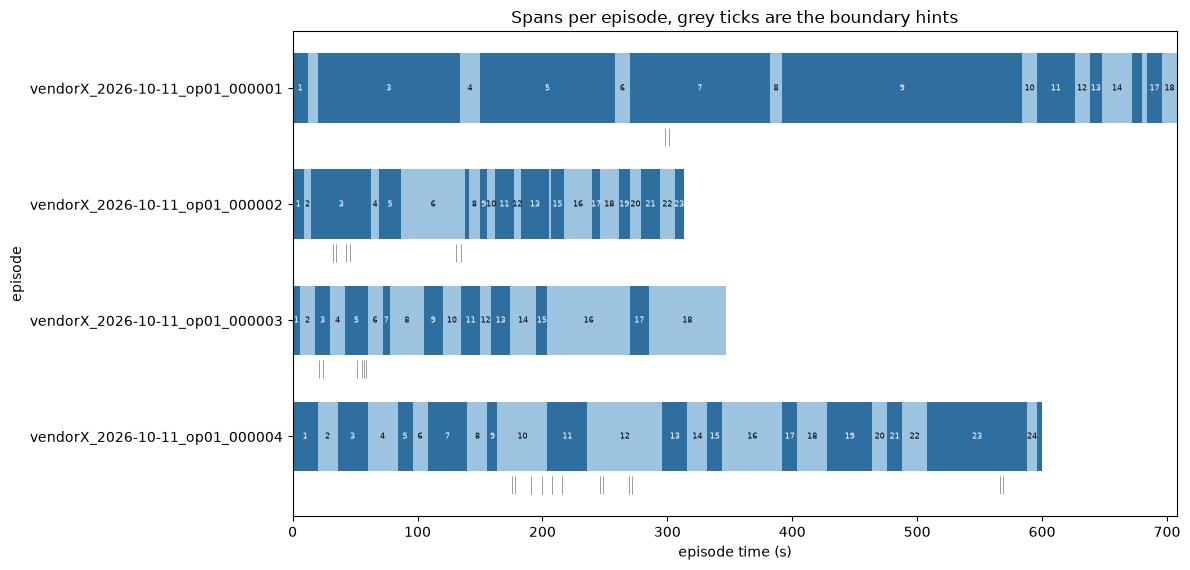

saved 10_spans_timeline.png


In [27]:
if labels_ok and check_df is not None and len(check_df):
    try:
        shades = ["#2f6f9f", "#9cc3e0"]
        txt = ["white", "black"]
        fig, ax = plt.subplots(figsize=(12, 1.0 * len(eps) + 1.8))
        for r, (eid, ep) in enumerate(eps.items()):
            sub = check_df[check_df["episode_id"] == eid]
            for s in sub.itertuples():
                if pd.isna(s.start_time) or pd.isna(s.end_time):
                    continue
                k = (int(s.span_no) - 1) % 2
                ax.broken_barh([(s.start_time, s.end_time - s.start_time)], (r - 0.3, 0.6), facecolors=shades[k])
                if s.end_time - s.start_time >= ep["duration"] * 0.012:
                    ax.text((s.start_time + s.end_time) / 2, r, str(int(s.span_no)), ha="center", va="center",
                            fontsize=6, color=txt[k])
            h = hints_df[hints_df["episode_id"] == eid]
            xs = list(h["start_time"]) + list(h["end_time"])
            if xs:
                ax.vlines(xs, r + 0.34, r + 0.5, color="0.55", linewidth=0.6)
        ax.set_yticks(range(len(eps)))
        ax.set_yticklabels(list(eps))
        ax.invert_yaxis()
        ax.set_xlim(0, max(ep["duration"] for ep in eps.values()))
        ax.set_xlabel("episode time (s)")
        ax.set_ylabel("episode")
        ax.set_title("Spans per episode, grey ticks are the boundary hints")
        fig.tight_layout()
        fig.savefig(REPORTS / "10_spans_timeline.png", dpi=150)
        plt.show()
        plt.close(fig)
        print("saved 10_spans_timeline.png")
    except Exception as e:
        print("figure failed:", repr(e))
else:
    print("skipped, no label files")

## Save the checks

Saves one row per span and writes language.json for every episode without a FAIL.

In [28]:
if labels_ok and check_df is not None:
    try:
        save_csv(check_df, REPORTS / "10_label_check.csv")
        print("saved 10_label_check.csv,", len(check_df), "rows")
        written = 0
        for r in ep_df.itertuples():
            path = eps[r.episode_id]["dir"] / "language.json"
            if r.status == "FAIL":
                note = " (an older language.json was left as it is)" if path.exists() else ""
                print(r.episode_id, "has a FAIL, no language.json" + note)
                continue
            sub = check_df[check_df["episode_id"] == r.episode_id]
            data = {
                "episode_id": r.episode_id,
                "language_instruction": lang_text[r.episode_id],
                "spans": [{"start_time": float(s.start_time), "end_time": float(s.end_time), "label": s.label,
                           "start_frame": int(s.start_frame), "end_frame": int(s.end_frame)} for s in sub.itertuples()],
            }
            path.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
            written += 1
        print("language.json written for", written, "of", len(eps), "episodes")
    except Exception as e:
        print("saving failed:", repr(e))
else:
    print("skipped, no label files")

saved 10_label_check.csv, 84 rows
language.json written for 4 of 4 episodes


## Hypothesis tests

A short table of the tests on the labels. Without label files they are marked as skipped.

In [29]:
HYP = [
    ("L1", "every episode has a language_instruction of at least 10 words"),
    ("L2", "every episode has at least one span"),
    ("L3", "spans are consecutive and cover the whole episode"),
    ("L4", "no empty labels"),
    ("L5", "no degenerate labels (above 50 words)"),
    ("L6", "percent of clean labels"),
    ("L7", "phrasing consistency"),
    ("L8", "span duration statistics per episode"),
]


def span_stats(eid):
    d = check_df.loc[check_df["episode_id"] == eid, "duration_s"].dropna().astype(float)
    if len(d) == 0:
        return f"{eid}: no spans"
    return f"{eid}: n={len(d)} min={d.min():.1f} median={d.median():.1f} max={d.max():.1f}"


try:
    if labels_ok and ep_df is not None and check_df is not None:
        n_ep = len(ep_df)
        ok1 = int((ep_df["instr_words"] >= 10).sum())
        ok2 = int((ep_df["spans"] >= 1).sum())
        bad3 = int(ep_df[["gaps", "overlaps", "bad_times"]].sum().sum() + ep_df[["unsorted", "bad_start", "bad_end"]].sum().sum())
        n_lab = len(check_df)
        n_cl = int(check_df["clean"].sum()) if n_lab else 0
        e4, e5 = int(ep_df["empty"].sum()), int(ep_df["over50"].sum())
        if phr:
            top_w = phr["top_first_words"][0] if phr["top_first_words"] else ["-", 0]
            m7 = f"{phr['distinct']} distinct labels of {phr['labels']}, {phr['used_more_than_once']} used more than once, top first word {top_w[0]} ({top_w[1]})"
        else:
            m7 = "not available"
        res = [
            (f"min {int(ep_df['instr_words'].min())} words, {ok1} of {n_ep} episodes ok", "PASS" if ok1 == n_ep else "FLAG"),
            (f"{ok2} of {n_ep} episodes have spans", "PASS" if ok2 == n_ep else "FLAG"),
            (f"{bad3} problems (gaps, overlaps, bad ends, unsorted, bad times)", "PASS" if bad3 == 0 else "FLAG"),
            (f"{e4} empty labels", "PASS" if e4 == 0 else "FLAG"),
            (f"{e5} labels over 50 words", "PASS" if e5 == 0 else "FLAG"),
            (f"{n_cl} of {n_lab} labels clean ({round(100 * n_cl / n_lab, 1) if n_lab else 0.0} percent)", "INFO"),
            (m7, "INFO"),
            (" | ".join(span_stats(e) for e in eps), "INFO"),
        ]
    else:
        res = [("no label files, part B skipped", "SKIP")] * len(HYP)
    hyp_df = pd.DataFrame([{"id": h[0], "hypothesis": h[1], "measured": m, "result": r} for h, (m, r) in zip(HYP, res)])
    save_csv(hyp_df, REPORTS / "10_hypothesis_check.csv")
    for r in hyp_df.itertuples():
        print(f"{r.id}  {r.result:<5} {r.hypothesis}")
        print(f"      {r.measured}")
except Exception as e:
    print("hypothesis tests failed:", repr(e))

L1  PASS  every episode has a language_instruction of at least 10 words
      min 19 words, 4 of 4 episodes ok
L2  PASS  every episode has at least one span
      4 of 4 episodes have spans
L3  PASS  spans are consecutive and cover the whole episode
      0 problems (gaps, overlaps, bad ends, unsorted, bad times)
L4  PASS  no empty labels
      0 empty labels
L5  PASS  no degenerate labels (above 50 words)
      0 labels over 50 words
L6  INFO  percent of clean labels
      84 of 84 labels clean (100.0 percent)
L7  INFO  phrasing consistency
      47 distinct labels of 84, 12 used more than once, top first word stir (21)
L8  INFO  span duration statistics per episode
      vendorX_2026-10-11_op01_000001: n=18 min=4.0 median=12.0 max=192.0 | vendorX_2026-10-11_op01_000002: n=23 min=2.0 median=9.0 max=51.0 | vendorX_2026-10-11_op01_000003: n=18 min=6.0 median=15.0 max=66.0 | vendorX_2026-10-11_op01_000004: n=25 min=4.0 median=20.0 max=80.0


## Summary and zip

Saves the summary json and puts all 10_ files from reports into share_10.zip.

In [30]:
try:
    part_b = bool(labels_ok and check_df is not None and ep_df is not None)
    summary10 = {
        "created": datetime.now().isoformat(timespec="seconds"),
        "flags": {"FORCE": FORCE, "MAKE_STORYBOARD": MAKE_STORYBOARD, "STORYBOARD_STEP_S": STORYBOARD_STEP_S,
                  "MAKE_REVIEW_VIDEO": MAKE_REVIEW_VIDEO, "REVIEW_STEP_S": REVIEW_STEP_S,
                  "REVIEW_PLAY_FPS": REVIEW_PLAY_FPS, "PANEL_HEIGHT": PANEL_HEIGHT},
        "episodes": {eid: {"duration_sec": ep["duration"], "frames": ep["frames"],
                           "storyboard_pages": story_pages.get(eid), "boundary_hints": hints_count.get(eid),
                           "review_video": review_info.get(eid)} for eid, ep in eps.items()},
        "templates_written": templates_written,
        "part_b_ran": part_b,
    }
    if part_b:
        total = len(check_df)
        n_cl = int(check_df["clean"].sum()) if total else 0
        summary10["labels"] = {
            "spans": total, "clean_labels": n_cl,
            "percent_clean": round(100 * n_cl / total, 2) if total else 0.0,
            "episodes_ok": [r.episode_id for r in ep_df.itertuples() if r.status == "OK"],
            "episodes_fail": {r.episode_id: r.reasons for r in ep_df.itertuples() if r.status == "FAIL"},
        }
        summary10["phrasing"] = phr
    if hyp_df is not None:
        summary10["hypotheses"] = {r.id: r.result for r in hyp_df.itertuples()}
    (REPORTS / "10_summary.json").write_text(
        json.dumps(summary10, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")

    zip_path = REPORTS / "share_10.zip"
    files = sorted(p for p in REPORTS.glob("10_*") if p.is_file())
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            z.write(p, arcname=p.name)

    print("episodes:", len(eps))
    print("storyboard pages:", story_pages if story_pages else "none")
    print("review videos:", {k: v["size_mb"] for k, v in review_info.items()} if review_info else "none")
    print("boundary hints:", hints_count if hints_count else "none")
    if part_b:
        print("labels:", summary10["labels"]["clean_labels"], "of", summary10["labels"]["spans"], "clean,",
              summary10["labels"]["percent_clean"], "percent")
        print("episodes with a FAIL:", list(summary10["labels"]["episodes_fail"]) or "none")
    else:
        print("part B skipped, waiting for 10_language.csv and 10_spans.csv")
    print("zip with", len(files), "files:", zip_path)
except Exception as e:
    print("summary failed:", repr(e))

episodes: 4
storyboard pages: {'vendorX_2026-10-11_op01_000001': 12, 'vendorX_2026-10-11_op01_000002': 6, 'vendorX_2026-10-11_op01_000003': 6, 'vendorX_2026-10-11_op01_000004': 10}
review videos: {'vendorX_2026-10-11_op01_000001': 22.56, 'vendorX_2026-10-11_op01_000002': 8.68, 'vendorX_2026-10-11_op01_000003': 10.55, 'vendorX_2026-10-11_op01_000004': 18.18}
boundary hints: {'vendorX_2026-10-11_op01_000001': 1, 'vendorX_2026-10-11_op01_000002': 3, 'vendorX_2026-10-11_op01_000003': 3, 'vendorX_2026-10-11_op01_000004': 6}
labels: 84 of 84 clean, 100.0 percent
episodes with a FAIL: none
zip with 9 files: C:\workstation\3RD YEAR\ego_pipeline\reports\share_10.zip
